In [2]:

from google.colab import drive
drive.mount('/content/drive')

import os

PROJECT_DIR = "/content/drive/MyDrive/PM25_project"

folders = [
    "data",
    "notebooks",
    "outputs",
    "figures",
    "models"
]

for folder in folders:
    path = os.path.join(PROJECT_DIR, folder)
    os.makedirs(path, exist_ok=True)
    print(f"Ready: {path}")

print("\nProject directory structure is ready.")


Mounted at /content/drive
Ready: /content/drive/MyDrive/PM25_project/data
Ready: /content/drive/MyDrive/PM25_project/notebooks
Ready: /content/drive/MyDrive/PM25_project/outputs
Ready: /content/drive/MyDrive/PM25_project/figures
Ready: /content/drive/MyDrive/PM25_project/models

Project directory structure is ready.


In [3]:

import os

PROJECT_DIR = "/content/drive/MyDrive/PM25_project"

for root, dirs, files in os.walk(PROJECT_DIR):
    level = root.replace(PROJECT_DIR, "").count(os.sep)
    indent = "    " * level

    print(f"{indent}{os.path.basename(root)}/")

    for file in sorted(files):
        print(f"{indent}    {file}")


PM25_project/
    .gitignore
    README.md
    SPEC.md
    requirements.txt
    data/
        city_day.csv
        heldout_city_test_features.csv
    outputs/
        baseline_results_validation.csv
        chosen_classifier.txt
        chosen_regression_model.txt
        classification_baseline_validation.csv
        classification_confusion_matrices_validation.csv
        classification_test_confusion_matrix.csv
        classification_test_metrics.csv
        classification_threshold_curves.csv
        final_classification_test_predictions.csv
        final_regression_test_predictions.csv
        final_test_metrics.csv
        final_unseen_city_test_predictions.csv
        linear_models_validation.csv
        linear_svm_confusion_matrix.csv
        model_comparison_validation.csv
        model_ready_dataset.csv
        prepared_city_daily.csv
        regression_methods.md
        regression_test_metrics_by_period.csv
        svr_training_details.csv
        unseen_city_test_metrics_b

In [4]:

import os

NOTEBOOK_DIR = "/content/drive/MyDrive/PM25_project/notebooks"

print("Notebooks in project folder:\n")

for file in sorted(os.listdir(NOTEBOOK_DIR)):
    if file.endswith(".ipynb"):
        path = os.path.join(NOTEBOOK_DIR, file)
        size_kb = os.path.getsize(path) / 1024
        print(f"{file} — {size_kb:.2f} KB")


Notebooks in project folder:

01_data_understanding.ipynb — 792.74 KB
02_features_baselines.ipynb — 57.43 KB
03_modeling.ipynb — 467.91 KB
04_test_and_errors.ipynb — 88.29 KB
05_final_visualizations.ipynb — 655.19 KB


In [5]:

from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/PM25_project")

spec_content = r"""
# PM2.5 Next-Day Forecasting — Project Specification

## 1. Project Overview

### Objective

Develop machine-learning models to predict next-day PM2.5 concentration
using historical air-quality measurements and pollutant-related features.

The prediction is made at the end of the current day using information
available up to that day.

### Problem Type

This project investigates two related tasks:

1. Regression: predict the next day's PM2.5 concentration.
2. Classification: predict whether the next day's PM2.5 concentration
   exceeds 90 µg/m³.

The classification threshold of 90 µg/m³ is a project-defined threshold,
not a claim that it represents every possible air-quality standard.

## 2. Dataset

The project uses the city-day air-quality dataset.

- Original dataset: city_day.csv
- Observations are organized by city and date.
- PM2.5 is the primary pollutant of interest.
- The dataset contains additional pollutant measurements.

The original dataset is retained privately in Google Drive and is not
included in the public GitHub repository.

## 3. Prediction Targets

### Regression Target

PM2.5_next_day: PM2.5 concentration on the day following the input date.

### Classification Target

A binary target is defined as:

- Class 0: next-day PM2.5 <= 90 µg/m³
- Class 1: next-day PM2.5 > 90 µg/m³

## 4. Data Preparation and Feature Engineering

The planned preparation process includes:

- Date parsing and chronological ordering.
- City-wise time-series processing.
- Missing-date handling and missing-value analysis.
- Construction of lagged PM2.5 features.
- Construction of rolling PM2.5 statistics.
- Use of pollutant measurements as explanatory features.
- Exclusion of AQI and AQI_Bucket to avoid target leakage.
- Missing-value imputation using training data.
- Encoding of categorical variables where required.

### Feature Set

The final modeling feature set includes:

- PM2.5
- PM2.5_lag_1
- PM2.5_lag_2
- PM2.5_lag_3
- PM2.5_lag_7
- PM2.5_roll_mean_3
- PM2.5_roll_mean_7
- NO
- NO2
- NOx
- NH3
- CO
- SO2
- O3
- Benzene
- Toluene

City is used as a categorical feature for pooled-city modeling.
It is excluded from the dedicated unseen-city evaluation.

## 5. City Selection and Evaluation Groups

The pooled modeling group consists of:

- Delhi
- Lucknow
- Chennai
- Hyderabad
- Bengaluru
- Patna

Mumbai and Guwahati are reserved as held-out cities for evaluating
generalization to cities not used during pooled model training.

The city selection and coverage decisions are documented in the
project's data-preparation work.

## 6. Chronological Data Splitting

Data is divided chronologically using the target date to prevent
future information from entering model training.

- Training: target dates in 2015–2018.
- Validation: target dates in 2019.
- Test: target dates in January–July 2020.

The test period is further examined in relation to the lockdown
cutoff of 25 March 2020.

The test set is reserved for final evaluation and is not used for
model selection or hyperparameter tuning.

## 7. Baseline Models

Regression baselines:

1. Persistence baseline: use current-day PM2.5 as the next-day prediction.
2. Seven-day mean baseline: use the recent seven-day PM2.5 mean.

Classification baseline:

- Apply the 90 µg/m³ threshold to current-day PM2.5.

Baseline comparisons use comparable rows wherever required.

## 8. Candidate Modeling Approaches

### Regression

The planned candidate approaches include:

- Ordinary Least Squares
- Ridge Regression
- Lasso Regression
- Support Vector Regression
- Random Forest Regression
- Histogram-based Gradient Boosting Regression

### Classification

The planned candidate approaches include:

- Logistic Regression
- Linear Support Vector Classification
- Random Forest Classification

These are candidate methods. The final model choices are determined
by validation performance, not assumed in advance.

## 9. Model Selection

Regression models are compared using validation data.

Primary metric:

- Mean Absolute Error (MAE)

Additional metrics:

- Root Mean Squared Error (RMSE)
- Skill relative to the persistence baseline

Classification models are compared using validation data.

Metrics:

- Precision
- Recall
- F1-score
- Precision-Recall AUC
- Confusion matrix

The classification operating threshold is selected using validation
data and fixed before final test evaluation.

Preprocessing and hyperparameter tuning must be fitted using training
data only, with chronological validation procedures.

## 10. Final Evaluation

After model selection:

- Refit the selected regression model using training and validation data.
- Refit the selected classifier using training and validation data.
- Evaluate each final model on the reserved test set.
- Compare regression predictions with the persistence and seven-day
  mean baselines.
- Report performance for the full test period and the pre-lockdown
  and lockdown portions.
- Evaluate generalization to Mumbai and Guwahati using a model trained
  on pooled training cities without a City feature.
- Compare unseen-city predictions against persistence on the same rows.

Test results must not be used to revise model selection or thresholds.

## 11. Reproducibility and Project Outputs

The project is organized into:

- notebooks/: data understanding, feature engineering, modeling,
  and final testing.
- outputs/: prepared data, validation results, predictions, and reports.
- figures/: exploratory and model-evaluation visualizations.
- models/: saved final fitted models and metadata.

The project will include a README and dependency list to support
reproducibility.

## 12. Experiment Tracking and Transparency

Candidate models, preprocessing choices, hyperparameters, and
validation results are recorded in the project outputs.

Final model choices and test results are reported separately from
the original project plan.

The final test results are not used to claim that a model was
known to be the best before experimentation.

## 13. Privacy

The original raw dataset and other private or unnecessarily large
data files are not uploaded to the public GitHub repository.
"""

spec_path = PROJECT_DIR / "SPEC.md"
spec_path.write_text(spec_content.strip() + "\n", encoding="utf-8")

print("SPEC.md saved successfully.")
print("Location:", spec_path)
print("File size:", spec_path.stat().st_size, "bytes")


SPEC.md saved successfully.
Location: /content/drive/MyDrive/PM25_project/SPEC.md
File size: 6151 bytes


In [6]:
spec_path = "/content/drive/MyDrive/PM25_project/SPEC.md"

with open(spec_path, "r", encoding="utf-8") as f:
    print(f.read()[:1500])

# PM2.5 Next-Day Forecasting — Project Specification

## 1. Project Overview

### Objective

Develop machine-learning models to predict next-day PM2.5 concentration
using historical air-quality measurements and pollutant-related features.

The prediction is made at the end of the current day using information
available up to that day.

### Problem Type

This project investigates two related tasks:

1. Regression: predict the next day's PM2.5 concentration.
2. Classification: predict whether the next day's PM2.5 concentration
   exceeds 90 µg/m³.

The classification threshold of 90 µg/m³ is a project-defined threshold,
not a claim that it represents every possible air-quality standard.

## 2. Dataset

The project uses the city-day air-quality dataset.

- Original dataset: city_day.csv
- Observations are organized by city and date.
- PM2.5 is the primary pollutant of interest.
- The dataset contains additional pollutant measurements.

The original dataset is retained privately in Google 

In [7]:

from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/PM25_project")

readme_content = r"""
# PM2.5 Next-Day Forecasting Using Machine Learning

## Overview

This project explores the prediction of next-day PM2.5 concentration
using historical air-quality measurements and machine-learning
techniques.

It investigates two related tasks:

1. **Regression:** Predict the next day's PM2.5 concentration.
2. **Classification:** Predict whether next-day PM2.5 exceeds
   90 µg/m³.

The project follows a chronological evaluation strategy to avoid
using future observations when training models.

## Objectives

- Understand the temporal patterns and missingness in air-quality data.
- Engineer lag-based and rolling statistical features.
- Establish simple forecasting baselines.
- Compare multiple regression and classification approaches.
- Evaluate generalization to cities excluded from pooled model training.
- Analyze model errors and limitations.

## Dataset

The project uses a city-day air-quality dataset containing PM2.5
and other pollutant measurements.

The original raw dataset is not included in this public repository.

## Methodology

### Data Preparation

- Date parsing and chronological organization.
- City-wise time-series processing.
- Missing-value analysis and handling.
- Lag and rolling-window feature engineering.
- Exclusion of AQI and AQI_Bucket from the model features.

### Regression

The regression task predicts next-day PM2.5 concentration.

Candidate approaches include:

- Ordinary Least Squares
- Ridge Regression
- Lasso Regression
- Support Vector Regression
- Random Forest Regression
- Histogram-based Gradient Boosting

Regression baselines include persistence and a seven-day rolling mean.

### Classification

The classification task predicts whether next-day PM2.5 exceeds
90 µg/m³.

Candidate approaches include:

- Logistic Regression
- Linear Support Vector Classification
- Random Forest Classification

The classification operating threshold is selected using validation
data.

### Evaluation Strategy

The dataset is divided chronologically:

| Split | Target-date period |
|---|---|
| Training | 2015–2018 |
| Validation | 2019 |
| Test | January–July 2020 |

The test set is reserved for final evaluation.

Evaluation includes:

- Regression: MAE, RMSE, and skill relative to persistence.
- Classification: Precision, Recall, F1-score, PR-AUC, and confusion matrix.
- Temporal comparison of pre-lockdown and lockdown test periods.
- Generalization evaluation on held-out cities.

## Project Structure

```text
PM25_project/
├── README.md
├── SPEC.md
├── requirements.txt
├── .gitignore
├── notebooks/
│   ├── 01_data_understanding.ipynb
│   ├── 02_features_baselines.ipynb
│   ├── 03_modeling.ipynb
│   └── 04_test_and_errors.ipynb
├── models/
├── outputs/
└── figures/
```

## Tools and Libraries

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn
- Joblib
- Google Colab

## Reproducibility

The notebooks document the data preparation, feature engineering,
model development, and final evaluation workflow.

Install the required Python packages using:

```bash
pip install -r requirements.txt
```

## Results

Final model selections and validation results are documented in the
project outputs.

Final test metrics, model comparisons, and error analysis will be
added after the reserved test evaluation is completed.

## Limitations

- Air-quality measurements contain missing observations.
- Performance may vary across cities and time periods.
- Relationships learned from historical data do not establish
  causal relationships between pollutants.
- Generalization to unseen cities may be limited by differences
  in local environmental and measurement conditions.

## Project Specification

See [SPEC.md](SPEC.md) for the original project objectives,
data-splitting strategy, candidate models, and evaluation protocol.
"""

readme_path = PROJECT_DIR / "README.md"
readme_path.write_text(readme_content.strip() + "\n", encoding="utf-8")

print("README.md saved successfully.")
print("Location:", readme_path)
print("File size:", readme_path.stat().st_size, "bytes")


README.md saved successfully.
Location: /content/drive/MyDrive/PM25_project/README.md
File size: 3887 bytes


In [8]:

from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/PM25_project")

requirements = """numpy
pandas
matplotlib
seaborn
scikit-learn
scipy
joblib
jupyter
"""

requirements_path = PROJECT_DIR / "requirements.txt"
requirements_path.write_text(requirements, encoding="utf-8")

print("requirements.txt saved successfully.")
print(requirements_path)


requirements.txt saved successfully.
/content/drive/MyDrive/PM25_project/requirements.txt


In [9]:

gitignore_content = """
# Raw and prepared datasets
data/
outputs/model_ready_dataset.csv
outputs/prepared_city_daily.csv

# Python temporary files
__pycache__/
*.py[cod]
.ipynb_checkpoints/

# Environment files
.env
.venv/

# Temporary files
*.tmp
*.log
.DS_Store
"""

gitignore_path = PROJECT_DIR / ".gitignore"
gitignore_path.write_text(gitignore_content.strip() + "\n", encoding="utf-8")

print(".gitignore saved successfully.")
print(gitignore_path)


.gitignore saved successfully.
/content/drive/MyDrive/PM25_project/.gitignore


In [10]:

import pandas as pd
import os

PROJECT_DIR = "/content/drive/MyDrive/PM25_project"
OUTPUT_DIR = os.path.join(PROJECT_DIR, "outputs")

model_df = pd.read_csv(
    os.path.join(OUTPUT_DIR, "model_ready_dataset.csv"),
    parse_dates=["Date", "Target_Date"]
)

prepared_df = pd.read_csv(
    os.path.join(OUTPUT_DIR, "prepared_city_daily.csv"),
    parse_dates=["Date"]
)

print("MODEL-READY DATASET")
print("Shape:", model_df.shape)
print("\nRows per split:")
print(model_df["Split"].value_counts(dropna=False))

print("\nTarget-date ranges by split:")
print(
    model_df.groupby("Split")["Target_Date"]
    .agg(["min", "max", "count"])
)

print("\nCities in model-ready dataset:")
print(sorted(model_df["City"].dropna().unique()))

print("\nPREPARED DATASET")
print("Shape:", prepared_df.shape)
print("Columns:", prepared_df.columns.tolist())
print("\nCities in prepared dataset:")
print(sorted(prepared_df["City"].dropna().unique()))


MODEL-READY DATASET
Shape: (11037, 22)

Rows per split:
Split
train         7751
validation    2188
test          1098
Name: count, dtype: int64

Target-date ranges by split:
                  min        max  count
Split                                  
test       2020-01-01 2020-07-01   1098
train      2015-01-02 2018-12-31   7751
validation 2019-01-01 2019-12-31   2188

Cities in model-ready dataset:
['Bengaluru', 'Chennai', 'Delhi', 'Hyderabad', 'Lucknow', 'Patna']

PREPARED DATASET
Shape: (12054, 25)
Columns: ['Date', 'City', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene', 'AQI', 'AQI_Bucket', 'Target_Date', 'PM2.5_next_day', 'PM2.5_lag_1', 'PM2.5_lag_2', 'PM2.5_lag_3', 'PM2.5_lag_7', 'PM2.5_roll_mean_3', 'PM2.5_roll_mean_7', 'Split']

Cities in prepared dataset:
['Bengaluru', 'Chennai', 'Delhi', 'Hyderabad', 'Lucknow', 'Patna']


In [11]:

RAW_PATH = "/content/drive/MyDrive/PM25_project/data/city_day.csv"

raw_df = pd.read_csv(RAW_PATH, parse_dates=["Date"])

print("Original dataset shape:", raw_df.shape)

print("\nAll cities in original dataset:")
print(sorted(raw_df["City"].dropna().unique()))

print("\nHeld-out city availability:")

for city in ["Mumbai", "Guwahati"]:
    city_df = raw_df[raw_df["City"] == city]

    print(f"\n{city}")
    print("Rows:", len(city_df))

    if len(city_df) > 0:
        print("Date range:", city_df["Date"].min(), "to", city_df["Date"].max())
        print("PM2.5 available:", city_df["PM2.5"].notna().sum())
        print("PM2.5 missing:", city_df["PM2.5"].isna().sum())


Original dataset shape: (29531, 16)

All cities in original dataset:
['Ahmedabad', 'Aizawl', 'Amaravati', 'Amritsar', 'Bengaluru', 'Bhopal', 'Brajrajnagar', 'Chandigarh', 'Chennai', 'Coimbatore', 'Delhi', 'Ernakulam', 'Gurugram', 'Guwahati', 'Hyderabad', 'Jaipur', 'Jorapokhar', 'Kochi', 'Kolkata', 'Lucknow', 'Mumbai', 'Patna', 'Shillong', 'Talcher', 'Thiruvananthapuram', 'Visakhapatnam']

Held-out city availability:

Mumbai
Rows: 2009
Date range: 2015-01-01 00:00:00 to 2020-07-01 00:00:00
PM2.5 available: 784
PM2.5 missing: 1225

Guwahati
Rows: 502
Date range: 2019-02-16 00:00:00 to 2020-07-01 00:00:00
PM2.5 available: 501
PM2.5 missing: 1


In [12]:

import json
from pathlib import Path

notebook_path = Path(
    "/content/drive/MyDrive/PM25_project/notebooks/02_features_baselines.ipynb"
)

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

keywords = [
    "reindex",
    "rolling",
    "lag_1",
    "Target_Date",
    "prepared_city_daily",
    "PM2.5_next_day"
]

for i, cell in enumerate(notebook["cells"]):
    if cell["cell_type"] != "code":
        continue

    source = "".join(cell["source"])

    if any(keyword in source for keyword in keywords):
        print(f"\n{'='*60}")
        print(f"CELL {i}")
        print("="*60)
        print(source[:5000])



CELL 0

from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import pandas as pd
import numpy as np

PROJECT_DIR = Path("/content/drive/MyDrive/PM25_project")
OUTPUT_DIR = PROJECT_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

model_path = OUTPUT_DIR / "model_ready_dataset.csv"

model_df = pd.read_csv(
    model_path,
    parse_dates=["Date", "Target_Date"]
)

print("Dataset loaded:", model_path.exists())
print("Shape:", model_df.shape)

print("\nRows per split:")
print(model_df["Split"].value_counts())

display(model_df.head())


CELL 2

# Metadata and target columns are not predictor features
excluded_cols = [
    "City", "Date", "Target_Date", "Split",
    "PM2.5_next_day", "baseline_comparable"
]

candidate_features = [
    col for col in model_df.columns
    if col not in excluded_cols
]

# Use training data only
train_df = model_df.loc[model_df["Split"] == "train"].copy()

missing_pct = (
    train_df[candidate_features]
    .isn

In [13]:

import json
from pathlib import Path

notebook_path = Path(
    "/content/drive/MyDrive/PM25_project/notebooks/01_data_understanding.ipynb"
)

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

keywords = [
    "reindex",
    "rolling",
    "resample",
    "shift(",
    "Target_Date",
    "PM2.5_next_day",
    "date_range"
]

for i, cell in enumerate(notebook["cells"]):
    if cell["cell_type"] != "code":
        continue

    source = "".join(cell["source"])

    if any(keyword in source for keyword in keywords):
        print(f"\n{'='*60}")
        print(f"CELL {i}")
        print("="*60)
        print(source[:6000])



CELL 9

import calendar
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Ensure Date is datetime
df["Date"] = pd.to_datetime(df["Date"])

# Full daily calendar for the overall dataset
all_dates = pd.date_range(
    df["Date"].min(),
    df["Date"].max(),
    freq="D"
)

# Create a complete city-date grid
cities = sorted(df["City"].dropna().unique())

full_index = pd.MultiIndex.from_product(
    [cities, all_dates],
    names=["City", "Date"]
)

# Reindex PM2.5 so dates without rows count as missing
pm25_daily = (
    df.drop_duplicates(["City", "Date"])
      .set_index(["City", "Date"])["PM2.5"]
      .reindex(full_index)
)

coverage_df = pm25_daily.rename("PM2.5").reset_index()
coverage_df["Year"] = coverage_df["Date"].dt.year
coverage_df["available"] = coverage_df["PM2.5"].notna()

# Percentage of calendar days with PM2.5 available
coverage = coverage_df.pivot_table(
    index="City",
    columns="Year",
    values="available",
    aggfunc="mean"
) * 100

In [14]:

import pandas as pd
import numpy as np
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/PM25_project")
RAW_PATH = PROJECT_DIR / "data" / "city_day.csv"

raw_df = pd.read_csv(RAW_PATH, parse_dates=["Date"])

heldout_cities = ["Mumbai", "Guwahati"]

# Use the same overall calendar range as the original preparation
all_dates = pd.date_range(
    raw_df["Date"].min(),
    raw_df["Date"].max(),
    freq="D"
)

# Features retained in the final pooled modeling dataset
selected_features = [
    "PM2.5",
    "PM2.5_lag_1",
    "PM2.5_lag_2",
    "PM2.5_lag_3",
    "PM2.5_lag_7",
    "PM2.5_roll_mean_3",
    "PM2.5_roll_mean_7",
    "NO",
    "NO2",
    "NOx",
    "NH3",
    "CO",
    "SO2",
    "O3",
    "Benzene",
    "Toluene"
]

heldout_daily = []

for city in heldout_cities:

    city_data = (
        raw_df.loc[raw_df["City"] == city]
        .drop_duplicates("Date")
        .set_index("Date")
        .sort_index()
    )

    # Reindex to a complete daily calendar
    city_data = city_data.reindex(all_dates)

    city_data.index.name = "Date"
    city_data = city_data.reset_index()
    city_data["City"] = city

    # Create next-day target and target date
    city_data["Target_Date"] = (
        city_data["Date"] + pd.Timedelta(days=1)
    )

    city_data["PM2.5_next_day"] = (
        city_data["PM2.5"].shift(-1)
    )

    # Generate lag features
    for lag in [1, 2, 3, 7]:
        city_data[f"PM2.5_lag_{lag}"] = (
            city_data["PM2.5"].shift(lag)
        )

    # Generate rolling means
    city_data["PM2.5_roll_mean_3"] = (
        city_data["PM2.5"]
        .rolling(window=3, min_periods=3)
        .mean()
    )

    city_data["PM2.5_roll_mean_7"] = (
        city_data["PM2.5"]
        .rolling(window=7, min_periods=7)
        .mean()
    )

    heldout_daily.append(city_data)

# Combine the two cities
heldout_df = pd.concat(
    heldout_daily,
    ignore_index=True
)

# Assign splits using target dates, exactly as in the original project
heldout_df["Split"] = np.select(
    [
        heldout_df["Target_Date"].between(
            "2015-01-01", "2018-12-31"
        ),
        heldout_df["Target_Date"].between(
            "2019-01-01", "2019-12-31"
        ),
        heldout_df["Target_Date"].between(
            "2020-01-01", "2020-07-01"
        )
    ],
    ["train", "validation", "test"],
    default="outside"
)

# Keep eligible test rows
heldout_test_df = heldout_df.loc[
    (heldout_df["Split"] == "test")
    & heldout_df["PM2.5"].notna()
    & heldout_df["PM2.5_next_day"].notna()
].copy()

# Flag rows where both persistence and 7-day mean are available
heldout_test_df["baseline_comparable"] = (
    heldout_test_df["PM2.5_roll_mean_7"].notna()
)

# Keep metadata, selected features, target and baseline flag
heldout_test_df = heldout_test_df[
    ["City", "Date", "Target_Date"]
    + selected_features
    + ["PM2.5_next_day", "baseline_comparable"]
].copy()

# Save privately inside the ignored data folder
save_path = (
    PROJECT_DIR / "data" / "heldout_city_test_features.csv"
)

heldout_test_df.to_csv(save_path, index=False)

# Display checks
print("Held-out test dataset shape:", heldout_test_df.shape)

print("\nRows available by city:")
print(heldout_test_df.groupby("City").size())

print("\nTarget-date range:")
print(
    heldout_test_df.groupby("City")["Target_Date"]
    .agg(["min", "max"])
)

print("\nRows available for both baselines:")
print(
    heldout_test_df.groupby("City")["baseline_comparable"]
    .sum()
)

print("\nMissing target values:")
print(heldout_test_df["PM2.5_next_day"].isna().sum())

print("\nSaved privately to:", save_path)


Held-out test dataset shape: (364, 21)

Rows available by city:
City
Guwahati    181
Mumbai      183
dtype: int64

Target-date range:
                min        max
City                          
Guwahati 2020-01-01 2020-07-01
Mumbai   2020-01-01 2020-07-01

Rows available for both baselines:
City
Guwahati    175
Mumbai      183
Name: baseline_comparable, dtype: int64

Missing target values:
0

Saved privately to: /content/drive/MyDrive/PM25_project/data/heldout_city_test_features.csv


In [15]:

import json
from pathlib import Path

notebook_path = Path(
    "/content/drive/MyDrive/PM25_project/notebooks/03_modeling.ipynb"
)

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

keywords = [
    "SVR(",
    "LogisticRegression(",
    "C=100",
    "gamma",
    "epsilon",
    "threshold",
    "make_preprocessor",
    "classification"
]

for i, cell in enumerate(notebook["cells"]):
    if cell["cell_type"] != "code":
        continue

    source = "".join(cell["source"])

    if any(keyword.lower() in source.lower() for keyword in keywords):
        print(f"\n{'='*60}")
        print(f"CELL {i}")
        print("="*60)
        print(source[:5000])



CELL 2

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

def make_preprocessor():
    # Numeric features: fill missing values, then standardize
    numeric_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    # Categorical feature: convert City into indicator columns
    categorical_transformer = OneHotEncoder(
        handle_unknown="ignore"
    )

    # Apply the correct transformation to each column type
    preprocessor = ColumnTransformer(
        transformers=[
            ("num", numeric_transformer, numeric_features),
            ("city", categorical_transformer, categorical_features)
        ],
        remainder="drop"
    )

    return preprocessor

print("Preprocessing function defined successfully.")


CELL 3

from sklearn.linear_model import LinearRegre

In [16]:
# Check that the final modeling inputs are available

required_variables = [
    "model_df",
    "numeric_features",
    "categorical_features",
    "make_preprocessor"
]

for name in required_variables:
    print(f"{name}: {'AVAILABLE' if name in globals() else 'MISSING'}")

print("\nNumeric features:")
print(numeric_features if "numeric_features" in globals() else "Not available")

print("\nCategorical features:")
print(categorical_features if "categorical_features" in globals() else "Not available")

model_df: AVAILABLE
numeric_features: MISSING
categorical_features: MISSING
make_preprocessor: MISSING

Numeric features:
Not available

Categorical features:
Not available


In [17]:
# Recreate the feature lists used during model development

numeric_features = [
    "PM2.5",
    "PM2.5_lag_1",
    "PM2.5_lag_2",
    "PM2.5_lag_3",
    "PM2.5_lag_7",
    "PM2.5_roll_mean_3",
    "PM2.5_roll_mean_7",
    "NO",
    "NO2",
    "NOx",
    "NH3",
    "CO",
    "SO2",
    "O3",
    "Benzene",
    "Toluene"
]

categorical_features = ["City"]

print("Numeric features:", len(numeric_features))
print("Categorical features:", categorical_features)

# Verify that every feature exists in model_df
required_columns = numeric_features + categorical_features

missing_columns = [
    col for col in required_columns
    if col not in model_df.columns
]

print("\nMissing columns:", missing_columns)

Numeric features: 16
Categorical features: ['City']

Missing columns: []


In [18]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

def make_preprocessor():
    numeric_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_transformer = OneHotEncoder(
        handle_unknown="ignore"
    )

    preprocessor = ColumnTransformer(
        transformers=[
            ("num", numeric_transformer, numeric_features),
            ("city", categorical_transformer, categorical_features)
        ],
        remainder="drop"
    )

    return preprocessor

print("Preprocessing function recreated successfully.")

Preprocessing function recreated successfully.


In [19]:
# Combine training and validation data

train_val_df = model_df[
    model_df["Split"].isin(["train", "validation"])
].copy()

# Keep test data separate
test_df = model_df[
    model_df["Split"] == "test"
].copy()

# Regression features and target
X_train_val = train_val_df[
    numeric_features + categorical_features
]

y_train_val = train_val_df["PM2.5_next_day"]

# Classification target
y_train_val_cls = (
    train_val_df["PM2.5_next_day"] > 90
).astype(int)

# Test features and targets (do not predict yet)
X_test = test_df[
    numeric_features + categorical_features
]

y_test = test_df["PM2.5_next_day"]

y_test_cls = (
    test_df["PM2.5_next_day"] > 90
).astype(int)

print("Training + validation rows:", len(train_val_df))
print("Test rows:", len(test_df))

print("\nRegression training shape:", X_train_val.shape)
print("Regression target shape:", y_train_val.shape)

print("\nClassification target distribution:")
print(y_train_val_cls.value_counts().sort_index())

print("\nTest target shape:", y_test.shape)

Training + validation rows: 9939
Test rows: 1098

Regression training shape: (9939, 17)
Regression target shape: (9939,)

Classification target distribution:
PM2.5_next_day
0    7146
1    2793
Name: count, dtype: int64

Test target shape: (1098,)


In [20]:
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error
from sklearn.pipeline import Pipeline
import time

# Build final SVR pipeline
final_regression_model = Pipeline(steps=[
    ("preprocessor", make_preprocessor()),
    ("model", SVR(
        kernel="rbf",
        C=100,
        gamma=0.01,
        epsilon=0.1
    ))
])

# Fit on training + validation data
start_time = time.perf_counter()

final_regression_model.fit(
    X_train_val,
    y_train_val
)

training_time = time.perf_counter() - start_time

print("Final SVR training completed.")
print("Training rows:", len(X_train_val))
print("Training time (seconds):", round(training_time, 2))
print("Test predictions generated: 0")

Final SVR training completed.
Training rows: 9939
Training time (seconds): 8.12
Test predictions generated: 0


In [21]:
from sklearn.linear_model import LogisticRegression
import time

# Build final Logistic Regression pipeline
final_classifier = Pipeline(steps=[
    ("preprocessor", make_preprocessor()),
    ("model", LogisticRegression(
        max_iter=2000,
        class_weight=None,
        random_state=42
    ))
])

# Fit on training + validation data
start_time = time.perf_counter()

final_classifier.fit(
    X_train_val,
    y_train_val_cls
)

classifier_training_time = time.perf_counter() - start_time

print("Final Logistic Regression training completed.")
print("Training rows:", len(X_train_val))
print("Training time (seconds):",
      round(classifier_training_time, 2))
print("Operating threshold: 0.40")
print("Test predictions generated: 0")

Final Logistic Regression training completed.
Training rows: 9939
Training time (seconds): 0.08
Operating threshold: 0.40
Test predictions generated: 0


In [22]:
import os
import pandas as pd

heldout_path = (
    "/content/drive/MyDrive/PM25_project/data/"
    "heldout_city_test_features.csv"
)

print("File exists:", os.path.exists(heldout_path))

if os.path.exists(heldout_path):
    heldout_df = pd.read_csv(heldout_path)

    print("Dataset shape:", heldout_df.shape)
    print("\nCities:")
    print(heldout_df["City"].value_counts())

    print("\nTarget missing values:",
          heldout_df["PM2.5_next_day"].isna().sum())

File exists: True
Dataset shape: (364, 21)

Cities:
City
Mumbai      183
Guwahati    181
Name: count, dtype: int64

Target missing values: 0


In [23]:
# Prepare pooled training data without the City feature

unseen_numeric_features = numeric_features.copy()

X_unseen_train = train_val_df[unseen_numeric_features]

y_unseen_train = train_val_df["PM2.5_next_day"]

# Prepare held-out city features
X_heldout = heldout_df[unseen_numeric_features]

y_heldout = heldout_df["PM2.5_next_day"]

print("Unseen-city training rows:", len(X_unseen_train))
print("Held-out evaluation rows:", len(X_heldout))

print("\nTraining features:", X_unseen_train.shape)
print("Held-out features:", X_heldout.shape)

print("\nCity feature included:", "City" in X_unseen_train.columns)
print("\nHeld-out cities:")
print(heldout_df["City"].value_counts())

Unseen-city training rows: 9939
Held-out evaluation rows: 364

Training features: (9939, 16)
Held-out features: (364, 16)

City feature included: False

Held-out cities:
City
Mumbai      183
Guwahati    181
Name: count, dtype: int64


In [24]:
# Build unseen-city SVR pipeline (without City encoding)

unseen_city_model = Pipeline(steps=[
    ("preprocessor", ColumnTransformer(
        transformers=[
            ("num",
             Pipeline(steps=[
                 ("imputer", SimpleImputer(strategy="median")),
                 ("scaler", StandardScaler())
             ]),
             unseen_numeric_features)
        ],
        remainder="drop"
    )),
    ("model", SVR(
        kernel="rbf",
        C=100,
        gamma=0.01,
        epsilon=0.1
    ))
])

# Train using pooled training + validation data
start_time = time.perf_counter()

unseen_city_model.fit(
    X_unseen_train,
    y_unseen_train
)

unseen_training_time = time.perf_counter() - start_time

print("Unseen-city SVR training completed.")
print("Training rows:", len(X_unseen_train))
print("Training time (seconds):",
      round(unseen_training_time, 2))
print("Held-out predictions generated: 0")

Unseen-city SVR training completed.
Training rows: 9939
Training time (seconds): 5.32
Held-out predictions generated: 0


In [25]:
import os
import joblib

# Create models directory
models_dir = (
    "/content/drive/MyDrive/PM25_project/models"
)

os.makedirs(models_dir, exist_ok=True)

# Save all three trained models
joblib.dump(
    final_regression_model,
    f"{models_dir}/best_regression_model.joblib"
)

joblib.dump(
    final_classifier,
    f"{models_dir}/best_classifier.joblib"
)

joblib.dump(
    unseen_city_model,
    f"{models_dir}/unseen_city_regression_model.joblib"
)

# Verify saved files
print("Model files:")

for filename in os.listdir(models_dir):
    print(filename)

print("\nTotal saved models:",
      len(os.listdir(models_dir)))

Model files:
best_regression_model.joblib
best_classifier.joblib
unseen_city_regression_model.joblib

Total saved models: 3


In [26]:
import os
import joblib

models_dir = "/content/drive/MyDrive/PM25_project/models"

model_files = [
    "best_regression_model.joblib",
    "best_classifier.joblib",
    "unseen_city_regression_model.joblib"
]

for filename in model_files:
    filepath = os.path.join(models_dir, filename)

    loaded_model = joblib.load(filepath)

    size_mb = os.path.getsize(filepath) / (1024 ** 2)

    print(f"File: {filename}")
    print(f"Loaded type: {type(loaded_model).__name__}")
    print(f"File size: {size_mb:.2f} MB")
    print("Load successful:", loaded_model is not None)
    print("-" * 50)

File: best_regression_model.joblib
Loaded type: Pipeline
File size: 1.85 MB
Load successful: True
--------------------------------------------------
File: best_classifier.joblib
Loaded type: Pipeline
File size: 0.00 MB
Load successful: True
--------------------------------------------------
File: unseen_city_regression_model.joblib
Loaded type: Pipeline
File size: 1.40 MB
Load successful: True
--------------------------------------------------


In [27]:
print("Pooled test rows:", len(test_df))

print("\nBaseline comparability:")
print(test_df["baseline_comparable"].value_counts(dropna=False))

print("\nMissing baseline values:")
print(
    test_df[
        ["PM2.5", "PM2.5_roll_mean_7"]
    ].isna().sum()
)

print("\nTest target date range:")
print(
    test_df["Target_Date"].min(),
    "to",
    test_df["Target_Date"].max()
)

Pooled test rows: 1098

Baseline comparability:
baseline_comparable
True    1098
Name: count, dtype: int64

Missing baseline values:
PM2.5                0
PM2.5_roll_mean_7    0
dtype: int64

Test target date range:
2020-01-01 00:00:00 to 2020-07-01 00:00:00


In [28]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Generate final test predictions
test_predictions = final_regression_model.predict(X_test)

# Store predictions alongside actual values
regression_test_results = test_df[
    ["City", "Target_Date", "PM2.5_next_day",
     "PM2.5", "PM2.5_roll_mean_7"]
].copy()

regression_test_results["SVR_prediction"] = test_predictions

# Calculate metrics
def calculate_regression_metrics(actual, predicted):
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted))
    }

overall_results = {
    "SVR": calculate_regression_metrics(
        regression_test_results["PM2.5_next_day"],
        regression_test_results["SVR_prediction"]
    ),
    "Persistence": calculate_regression_metrics(
        regression_test_results["PM2.5_next_day"],
        regression_test_results["PM2.5"]
    ),
    "7-day mean": calculate_regression_metrics(
        regression_test_results["PM2.5_next_day"],
        regression_test_results["PM2.5_roll_mean_7"]
    )
}

overall_metrics_df = pd.DataFrame(overall_results).T
print("OVERALL TEST RESULTS")
display(overall_metrics_df.round(4))

# Pre-lockdown and lockdown evaluation
regression_test_results["Period"] = np.where(
    regression_test_results["Target_Date"] < "2020-03-25",
    "Pre-lockdown",
    "Lockdown"
)

period_results = []

for period, group in regression_test_results.groupby("Period"):
    for model_name, prediction_column in [
        ("SVR", "SVR_prediction"),
        ("Persistence", "PM2.5"),
        ("7-day mean", "PM2.5_roll_mean_7")
    ]:
        metrics = calculate_regression_metrics(
            group["PM2.5_next_day"],
            group[prediction_column]
        )

        period_results.append({
            "Period": period,
            "Model": model_name,
            "Rows": len(group),
            "MAE": metrics["MAE"],
            "RMSE": metrics["RMSE"]
        })

period_metrics_df = pd.DataFrame(period_results)

print("\nRESULTS BY PERIOD")
display(period_metrics_df.round(4))

OVERALL TEST RESULTS


,MAE,RMSE
SVR,11.4550,18.6468
Persistence,11.6316,19.4390
7-day mean,14.1057,22.4793



RESULTS BY PERIOD


,Period,Model,Rows,MAE,RMSE
0,Lockdown,SVR,594,7.8721,11.4096
1,Lockdown,Persistence,594,7.8516,12.1381
2,Lockdown,7-day mean,594,8.8974,12.5836
3,Pre-lockdown,SVR,504,15.6778,24.5778
4,Pre-lockdown,Persistence,504,16.0865,25.4870
5,Pre-lockdown,7-day mean,504,20.2440,30.2366


In [29]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Generate final test predictions
test_predictions = final_regression_model.predict(X_test)

# Store predictions alongside actual values
regression_test_results = test_df[
    ["City", "Target_Date", "PM2.5_next_day",
     "PM2.5", "PM2.5_roll_mean_7"]
].copy()

regression_test_results["SVR_prediction"] = test_predictions

# Calculate metrics
def calculate_regression_metrics(actual, predicted):
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted))
    }

overall_results = {
    "SVR": calculate_regression_metrics(
        regression_test_results["PM2.5_next_day"],
        regression_test_results["SVR_prediction"]
    ),
    "Persistence": calculate_regression_metrics(
        regression_test_results["PM2.5_next_day"],
        regression_test_results["PM2.5"]
    ),
    "7-day mean": calculate_regression_metrics(
        regression_test_results["PM2.5_next_day"],
        regression_test_results["PM2.5_roll_mean_7"]
    )
}

overall_metrics_df = pd.DataFrame(overall_results).T
print("OVERALL TEST RESULTS")
display(overall_metrics_df.round(4))

# Pre-lockdown and lockdown evaluation
regression_test_results["Period"] = np.where(
    regression_test_results["Target_Date"] < "2020-03-25",
    "Pre-lockdown",
    "Lockdown"
)

period_results = []

for period, group in regression_test_results.groupby("Period"):
    for model_name, prediction_column in [
        ("SVR", "SVR_prediction"),
        ("Persistence", "PM2.5"),
        ("7-day mean", "PM2.5_roll_mean_7")
    ]:
        metrics = calculate_regression_metrics(
            group["PM2.5_next_day"],
            group[prediction_column]
        )

        period_results.append({
            "Period": period,
            "Model": model_name,
            "Rows": len(group),
            "MAE": metrics["MAE"],
            "RMSE": metrics["RMSE"]
        })

period_metrics_df = pd.DataFrame(period_results)

print("\nRESULTS BY PERIOD")
display(period_metrics_df.round(4))

OVERALL TEST RESULTS


,MAE,RMSE
SVR,11.4550,18.6468
Persistence,11.6316,19.4390
7-day mean,14.1057,22.4793



RESULTS BY PERIOD


,Period,Model,Rows,MAE,RMSE
0,Lockdown,SVR,594,7.8721,11.4096
1,Lockdown,Persistence,594,7.8516,12.1381
2,Lockdown,7-day mean,594,8.8974,12.5836
3,Pre-lockdown,SVR,504,15.6778,24.5778
4,Pre-lockdown,Persistence,504,16.0865,25.4870
5,Pre-lockdown,7-day mean,504,20.2440,30.2366


In [30]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    confusion_matrix,
    accuracy_score
)

# Generate test probabilities
test_probabilities = final_classifier.predict_proba(X_test)[:, 1]

# Apply the threshold selected using validation data
classification_threshold = 0.40
test_class_predictions = (
    test_probabilities >= classification_threshold
).astype(int)

# Calculate test metrics
classification_metrics = {
    "Threshold": classification_threshold,
    "Precision": precision_score(y_test_cls, test_class_predictions),
    "Recall": recall_score(y_test_cls, test_class_predictions),
    "F1": f1_score(y_test_cls, test_class_predictions),
    "PR_AUC": average_precision_score(y_test_cls, test_probabilities),
    "Accuracy": accuracy_score(y_test_cls, test_class_predictions)
}

classification_test_metrics_df = pd.DataFrame(
    [classification_metrics]
)

print("FINAL CLASSIFICATION TEST RESULTS")
display(classification_test_metrics_df.round(4))

# Confusion matrix
test_confusion_matrix = confusion_matrix(
    y_test_cls,
    test_class_predictions,
    labels=[0, 1]
)

confusion_matrix_df = pd.DataFrame(
    test_confusion_matrix,
    index=["Actual: Not Poor", "Actual: Poor"],
    columns=["Predicted: Not Poor", "Predicted: Poor"]
)

print("\nTEST CONFUSION MATRIX")
display(confusion_matrix_df)

FINAL CLASSIFICATION TEST RESULTS


,Threshold,Precision,Recall,F1,PR_AUC,Accuracy
0,0.4,0.7429,0.8609,0.7975,0.8652,0.9399



TEST CONFUSION MATRIX


,Predicted: Not Poor,Predicted: Poor
Actual: Not Poor,902,45
Actual: Poor,21,130


In [31]:
# Generate predictions for unseen cities
unseen_predictions = unseen_city_model.predict(X_heldout)

# Store actual values and predictions
unseen_test_results = heldout_df[
    ["City", "Target_Date", "PM2.5_next_day",
     "PM2.5", "PM2.5_roll_mean_7", "baseline_comparable"]
].copy()

unseen_test_results["SVR_prediction"] = unseen_predictions

# Metric calculation function
def calculate_regression_metrics(actual, predicted):
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted))
    }

# Evaluate model on all held-out rows
print("UNSEEN-CITY MODEL: ALL ROWS")

all_rows_metrics = calculate_regression_metrics(
    unseen_test_results["PM2.5_next_day"],
    unseen_test_results["SVR_prediction"]
)

display(pd.DataFrame([all_rows_metrics], index=["Unseen-city SVR"]).round(4))

# Fair comparison: only rows where both baselines are available
common_unseen = unseen_test_results[
    unseen_test_results["baseline_comparable"]
].copy()

print("\nUNSEEN-CITY COMMON-ROW COMPARISON")
print("Common rows:", len(common_unseen))

common_results = {}

for model_name, prediction_column in [
    ("Unseen-city SVR", "SVR_prediction"),
    ("Persistence", "PM2.5"),
    ("7-day mean", "PM2.5_roll_mean_7")
]:
    common_results[model_name] = calculate_regression_metrics(
        common_unseen["PM2.5_next_day"],
        common_unseen[prediction_column]
    )

common_unseen_metrics_df = pd.DataFrame(common_results).T
display(common_unseen_metrics_df.round(4))

# City-wise evaluation
print("\nCITY-WISE UNSEEN-CITY SVR RESULTS")

city_results = []

for city, group in unseen_test_results.groupby("City"):
    metrics = calculate_regression_metrics(
        group["PM2.5_next_day"],
        group["SVR_prediction"]
    )

    city_results.append({
        "City": city,
        "Rows": len(group),
        "MAE": metrics["MAE"],
        "RMSE": metrics["RMSE"],
        "Baseline-comparable rows": group["baseline_comparable"].sum()
    })

city_metrics_df = pd.DataFrame(city_results)
display(city_metrics_df.round(4))

UNSEEN-CITY MODEL: ALL ROWS


,MAE,RMSE
Unseen-city SVR,12.3333,21.7228



UNSEEN-CITY COMMON-ROW COMPARISON
Common rows: 358


,MAE,RMSE
Unseen-city SVR,12.1070,21.5404
Persistence,11.9959,22.9068
7-day mean,16.0898,25.8764



CITY-WISE UNSEEN-CITY SVR RESULTS


,City,Rows,MAE,RMSE,Baseline-comparable rows
0,Guwahati,181,16.9246,28.4656,175
1,Mumbai,183,7.7922,11.7120,183


In [32]:
import os

outputs_dir = "/content/drive/MyDrive/PM25_project/outputs"
os.makedirs(outputs_dir, exist_ok=True)

# 1. Pooled regression predictions
regression_test_results.to_csv(
    f"{outputs_dir}/final_regression_test_predictions.csv",
    index=False
)

# 2. Classification predictions
classification_test_results = test_df[
    ["City", "Target_Date", "PM2.5_next_day"]
].copy()

classification_test_results["Actual_Class"] = y_test_cls.values
classification_test_results["Predicted_Probability"] = test_probabilities
classification_test_results["Predicted_Class"] = test_class_predictions
classification_test_results["Threshold"] = classification_threshold

classification_test_results.to_csv(
    f"{outputs_dir}/final_classification_test_predictions.csv",
    index=False
)

# 3. Unseen-city predictions
unseen_test_results.to_csv(
    f"{outputs_dir}/final_unseen_city_test_predictions.csv",
    index=False
)

# Verify saved files
prediction_files = [
    "final_regression_test_predictions.csv",
    "final_classification_test_predictions.csv",
    "final_unseen_city_test_predictions.csv"
]

print("Saved prediction files:")

for filename in prediction_files:
    filepath = os.path.join(outputs_dir, filename)
    print(
        filename,
        "| Exists:", os.path.exists(filepath),
        "| Rows:", len(pd.read_csv(filepath))
    )

Saved prediction files:
final_regression_test_predictions.csv | Exists: True | Rows: 1098
final_classification_test_predictions.csv | Exists: True | Rows: 1098
final_unseen_city_test_predictions.csv | Exists: True | Rows: 364


In [33]:
import os
import pandas as pd

outputs_dir = "/content/drive/MyDrive/PM25_project/outputs"

prediction_files = [
    "final_regression_test_predictions.csv",
    "final_classification_test_predictions.csv",
    "final_unseen_city_test_predictions.csv"
]

for filename in prediction_files:
    filepath = os.path.join(outputs_dir, filename)

    if os.path.exists(filepath):
        saved_df = pd.read_csv(filepath)
        print(f"{filename}")
        print("  Rows:", len(saved_df))
        print("  Columns:", len(saved_df.columns))
        print("  File size:", round(os.path.getsize(filepath) / 1024, 2), "KB")
    else:
        print(f"MISSING: {filename}")
    print("-" * 50)

final_regression_test_predictions.csv
  Rows: 1098
  Columns: 7
  File size: 83.08 KB
--------------------------------------------------
final_classification_test_predictions.csv
  Rows: 1098
  Columns: 7
  File size: 57.2 KB
--------------------------------------------------
final_unseen_city_test_predictions.csv
  Rows: 364
  Columns: 7
  File size: 25.58 KB
--------------------------------------------------


In [34]:
# Collect pooled regression metrics
final_metric_rows = []

for model_name, metrics in overall_results.items():
    final_metric_rows.append({
        "Experiment": "Pooled regression",
        "Model": model_name,
        "Dataset": "Pooled test",
        "Rows": len(regression_test_results),
        "MAE": metrics["MAE"],
        "RMSE": metrics["RMSE"],
        "Precision": None,
        "Recall": None,
        "F1": None,
        "PR_AUC": None
    })

# Collect classification metrics
final_metric_rows.append({
    "Experiment": "Classification",
    "Model": "Logistic Regression",
    "Dataset": "Pooled test",
    "Rows": len(classification_test_results),
    "MAE": None,
    "RMSE": None,
    "Precision": classification_metrics["Precision"],
    "Recall": classification_metrics["Recall"],
    "F1": classification_metrics["F1"],
    "PR_AUC": classification_metrics["PR_AUC"]
})

# Collect unseen-city regression metrics
for model_name, metrics in common_results.items():
    final_metric_rows.append({
        "Experiment": "Unseen-city regression",
        "Model": model_name,
        "Dataset": "Mumbai + Guwahati (common rows)",
        "Rows": len(common_unseen),
        "MAE": metrics["MAE"],
        "RMSE": metrics["RMSE"],
        "Precision": None,
        "Recall": None,
        "F1": None,
        "PR_AUC": None
    })

final_test_metrics_df = pd.DataFrame(final_metric_rows)

metrics_path = f"{outputs_dir}/final_test_metrics.csv"
final_test_metrics_df.to_csv(metrics_path, index=False)

print("Saved:", metrics_path)
display(final_test_metrics_df.round(4))

Saved: /content/drive/MyDrive/PM25_project/outputs/final_test_metrics.csv


,Experiment,Model,Dataset,Rows,MAE,RMSE,Precision,Recall,F1,PR_AUC
0,Pooled regression,SVR,Pooled test,1098,11.4550,18.6468,NaN,NaN,NaN,NaN
1,Pooled regression,Persistence,Pooled test,1098,11.6316,19.4390,NaN,NaN,NaN,NaN
2,Pooled regression,7-day mean,Pooled test,1098,14.1057,22.4793,NaN,NaN,NaN,NaN
3,Classification,Logistic Regression,Pooled test,1098,NaN,NaN,0.7429,0.8609,0.7975,0.8652
4,Unseen-city regression,Unseen-city SVR,Mumbai + Guwahati (common rows),358,12.1070,21.5404,NaN,NaN,NaN,NaN
5,Unseen-city regression,Persistence,Mumbai + Guwahati (common rows),358,11.9959,22.9068,NaN,NaN,NaN,NaN
6,Unseen-city regression,7-day mean,Mumbai + Guwahati (common rows),358,16.0898,25.8764,NaN,NaN,NaN,NaN


In [35]:
# Save period-wise regression metrics
period_metrics_df.to_csv(
    f"{outputs_dir}/regression_test_metrics_by_period.csv",
    index=False
)

# Save city-wise unseen-city metrics
city_metrics_df.to_csv(
    f"{outputs_dir}/unseen_city_test_metrics_by_city.csv",
    index=False
)

# Save classification confusion matrix
confusion_matrix_df.to_csv(
    f"{outputs_dir}/classification_test_confusion_matrix.csv"
)

# Save detailed classification metrics
classification_test_metrics_df.to_csv(
    f"{outputs_dir}/classification_test_metrics.csv",
    index=False
)

print("Saved detailed evaluation files:")

detailed_files = [
    "regression_test_metrics_by_period.csv",
    "unseen_city_test_metrics_by_city.csv",
    "classification_test_confusion_matrix.csv",
    "classification_test_metrics.csv"
]

for filename in detailed_files:
    filepath = os.path.join(outputs_dir, filename)
    print(filename, "| Exists:", os.path.exists(filepath))

Saved detailed evaluation files:
regression_test_metrics_by_period.csv | Exists: True
unseen_city_test_metrics_by_city.csv | Exists: True
classification_test_confusion_matrix.csv | Exists: True
classification_test_metrics.csv | Exists: True


In [36]:
import os

project_dir = "/content/drive/MyDrive/PM25_project"

folders_to_check = [
    "notebooks",
    "models",
    "outputs",
    "figures",
    "data"
]

for folder in folders_to_check:
    folder_path = os.path.join(project_dir, folder)

    print(f"\n{folder}/")

    if os.path.exists(folder_path):
        for filename in sorted(os.listdir(folder_path)):
            print("  ", filename)
    else:
        print("  FOLDER MISSING")

print("\nROOT FILES")
for filename in sorted(os.listdir(project_dir)):
    if os.path.isfile(os.path.join(project_dir, filename)):
        print(" ", filename)


notebooks/
   01_data_understanding.ipynb
   02_features_baselines.ipynb
   03_modeling.ipynb
   04_test_and_errors.ipynb
   05_final_visualizations.ipynb

models/
   best_classifier.joblib
   best_regression_model.joblib
   unseen_city_regression_model.joblib

outputs/
   baseline_results_validation.csv
   chosen_classifier.txt
   chosen_regression_model.txt
   classification_baseline_validation.csv
   classification_confusion_matrices_validation.csv
   classification_test_confusion_matrix.csv
   classification_test_metrics.csv
   classification_threshold_curves.csv
   final_classification_test_predictions.csv
   final_regression_test_predictions.csv
   final_test_metrics.csv
   final_unseen_city_test_predictions.csv
   linear_models_validation.csv
   linear_svm_confusion_matrix.csv
   model_comparison_validation.csv
   model_ready_dataset.csv
   prepared_city_daily.csv
   regression_methods.md
   regression_test_metrics_by_period.csv
   svr_training_details.csv
   unseen_city_test_m

In [37]:
project_dir = "/content/drive/MyDrive/PM25_project"

gitignore_path = f"{project_dir}/.gitignore"

with open(gitignore_path, "r") as file:
    gitignore_content = file.read()

print("CURRENT .gitignore CONTENT")
print("-" * 50)
print(gitignore_content)

CURRENT .gitignore CONTENT
--------------------------------------------------
# Raw and prepared datasets
data/
outputs/model_ready_dataset.csv
outputs/prepared_city_daily.csv

# Python temporary files
__pycache__/
*.py[cod]
.ipynb_checkpoints/

# Environment files
.env
.venv/

# Temporary files
*.tmp
*.log
.DS_Store



In [38]:
gitignore_path = "/content/drive/MyDrive/PM25_project/.gitignore"

gitignore_content = """# Raw and prepared datasets
data/
outputs/model_ready_dataset.csv
outputs/prepared_city_daily.csv

# Python temporary files
__pycache__/
*.py[cod]
**/.ipynb_checkpoints/

# Environment files
.env
.venv/

# Temporary files
*.tmp
*.log
.DS_Store
"""

with open(gitignore_path, "w") as file:
    file.write(gitignore_content)

print("Updated .gitignore successfully.\n")
print(open(gitignore_path).read())

Updated .gitignore successfully.

# Raw and prepared datasets
data/
outputs/model_ready_dataset.csv
outputs/prepared_city_daily.csv

# Python temporary files
__pycache__/
*.py[cod]
**/.ipynb_checkpoints/

# Environment files
.env
.venv/

# Temporary files
*.tmp
*.log
.DS_Store



In [39]:
readme_path = "/content/drive/MyDrive/PM25_project/README.md"

with open(readme_path, "r") as file:
    readme_content = file.read()

print(readme_content)

# PM2.5 Next-Day Forecasting Using Machine Learning

## Overview

This project explores the prediction of next-day PM2.5 concentration
using historical air-quality measurements and machine-learning
techniques.

It investigates two related tasks:

1. **Regression:** Predict the next day's PM2.5 concentration.
2. **Classification:** Predict whether next-day PM2.5 exceeds
   90 µg/m³.

The project follows a chronological evaluation strategy to avoid
using future observations when training models.

## Objectives

- Understand the temporal patterns and missingness in air-quality data.
- Engineer lag-based and rolling statistical features.
- Establish simple forecasting baselines.
- Compare multiple regression and classification approaches.
- Evaluate generalization to cities excluded from pooled model training.
- Analyze model errors and limitations.

## Dataset

The project uses a city-day air-quality dataset containing PM2.5
and other pollutant measurements.

The original raw dataset is n

In [41]:
readme_path = "/content/drive/MyDrive/PM25_project/README.md"

readme_content = r"""# PM2.5 Next-Day Forecasting Using Machine Learning

## Overview

This project investigates the prediction of next-day PM2.5 concentration using historical air-quality measurements and machine-learning techniques.

It addresses two related tasks:

1. **Regression:** Predict the next day's PM2.5 concentration.
2. **Classification:** Predict whether next-day PM2.5 exceeds 90 µg/m³.

The project follows a chronological evaluation strategy to avoid using future observations when training models.

It also investigates whether a regression model trained on a group of cities can generalize to cities excluded from its training data.

## Objectives

- Understand temporal patterns and missingness in air-quality data.
- Engineer lag-based and rolling statistical features.
- Establish simple forecasting baselines.
- Compare multiple regression and classification approaches.
- Evaluate generalization to cities excluded from pooled model training.
- Analyze model errors and limitations.

## Dataset

The project uses a city-day air-quality dataset containing PM2.5 and other pollutant measurements.

The original raw dataset and prepared datasets are excluded from this public repository.

## Methodology

### Data Preparation

- Date parsing and chronological organization.
- City-wise time-series processing.
- Missing-value analysis and handling.
- Lag and rolling-window feature engineering.
- Exclusion of AQI and AQI_Bucket from model features.
- Chronological train, validation, and test splitting.

### Regression

The regression task predicts next-day PM2.5 concentration.

Candidate approaches:

- Ordinary Least Squares
- Ridge Regression
- Lasso Regression
- Support Vector Regression
- Random Forest Regression
- Histogram-based Gradient Boosting

Regression baselines:

- Persistence: current-day PM2.5.
- Seven-day rolling mean.

The selected regression model was an RBF Support Vector Regressor with C = 100, gamma = 0.01, and epsilon = 0.1.

### Classification

The classification task predicts whether next-day PM2.5 exceeds 90 µg/m³.

Candidate approaches:

- Logistic Regression
- Linear Support Vector Classification
- Random Forest Classification

Logistic Regression was selected using validation PR-AUC. Its operating threshold was fixed at 0.40 using validation data.

### Evaluation Strategy

The dataset is divided chronologically according to target date:

| Split | Target-date period |
|---|---|
| Training | 2015–2018 |
| Validation | 2019 |
| Test | January–July 2020 |

The test set was reserved for final evaluation and was not used for model selection or threshold tuning.

Evaluation includes:

- Regression: MAE and RMSE.
- Classification: Precision, Recall, F1-score, PR-AUC, Accuracy, and confusion matrix.
- Temporal comparison of pre-lockdown and lockdown test periods.
- Generalization evaluation on held-out cities.

### Unseen-City Experiment

Mumbai and Guwahati were excluded from pooled-city model training.

A separate regression model was trained using the pooled training and validation data, without the City feature, and evaluated on these two held-out cities.

This experiment assesses generalization to cities not represented during model training.

## Results

### 1. Pooled Regression — Validation

The RBF SVR achieved the lowest validation MAE among the evaluated regression candidates.

| Model | Validation MAE | Validation RMSE |
|---|---:|---:|
| SVR (RBF) | 15.6688 | 27.6487 |
| Random Forest | 15.8567 | 27.6034 |
| Histogram Gradient Boosting | 16.2157 | 27.8004 |
| Persistence | 16.3761 | 29.8570 |
| Seven-day rolling mean | 21.2331 | 37.1337 |

### 2. Pooled Regression — Final Test

| Model | Test MAE | Test RMSE |
|---|---:|---:|
| **SVR (RBF)** | **11.4550** | **18.6468** |
| Persistence | 11.6316 | 19.4390 |
| Seven-day rolling mean | 14.1057 | 22.4793 |

The selected SVR outperformed both baselines on overall test MAE and RMSE.

Compared with persistence, it reduced MAE by approximately 1.52% and RMSE by approximately 4.07%.

#### Performance by Period

The test period was divided using 25 March 2020 as the cutoff.

| Period | Model | Rows | MAE | RMSE |
|---|---|---:|---:|---:|
| Pre-lockdown | SVR | 504 | 15.6778 | 24.5778 |
| Pre-lockdown | Persistence | 504 | 16.0865 | 25.4870 |
| Pre-lockdown | Seven-day mean | 504 | 20.2440 | 30.2366 |
| Lockdown period | SVR | 594 | 7.8721 | 11.4096 |
| Lockdown period | Persistence | 594 | 7.8516 | 12.1381 |
| Lockdown period | Seven-day mean | 594 | 8.8974 | 12.5836 |

The SVR performed better than persistence on both metrics before the cutoff. During the lockdown period, persistence had marginally lower MAE, while SVR had lower RMSE.

### 3. Classification — Final Test

Selected model: Logistic Regression.

Operating threshold: 0.40.

| Metric | Test result |
|---|---:|
| Precision | 0.7429 |
| Recall | 0.8609 |
| F1-score | 0.7975 |
| PR-AUC | 0.8652 |
| Accuracy | 0.9399 |

#### Confusion Matrix

| | Predicted: Not Poor | Predicted: Poor |
|---|---:|---:|
| Actual: Not Poor | 902 | 45 |
| Actual: Poor | 21 | 130 |

The classifier identified 130 of the 151 actual poor-air-quality days in the test set.

The test PR-AUC was lower than the validation PR-AUC of 0.9240, indicating a reduction in classification performance on unseen data.

### 4. Unseen-City Regression — Final Test

The separate SVR model was evaluated on Mumbai and Guwahati.

Overall model-only evaluation:

| Model | Rows | MAE | RMSE |
|---|---:|---:|---:|
| Unseen-city SVR | 364 | 12.3333 | 21.7228 |

For a fair comparison with both baselines, 358 rows with available baseline values were used:

| Model | Rows | MAE | RMSE |
|---|---:|---:|---:|
| Unseen-city SVR | 358 | 12.1070 | 21.5404 |
| Persistence | 358 | 11.9959 | 22.9068 |
| Seven-day rolling mean | 358 | 16.0898 | 25.8764 |

#### City-wise Performance

| City | Rows | MAE | RMSE |
|---|---:|---:|---:|
| Guwahati | 181 | 16.9246 | 28.4656 |
| Mumbai | 183 | 7.7922 | 11.7120 |

The unseen-city SVR achieved lower RMSE than persistence and outperformed the seven-day mean baseline on both metrics in the common-row comparison. However, persistence achieved slightly lower MAE.

Performance differed considerably between Mumbai and Guwahati, highlighting the challenges of generalizing across cities.

## Project Structure

```text
PM25_project/
├── README.md
├── SPEC.md
├── requirements.txt
├── .gitignore
├── notebooks/
│   ├── 01_data_understanding.ipynb
│   ├── 02_features_baselines.ipynb
│   ├── 03_modeling.ipynb
│   └── 04_test_and_errors.ipynb
├── models/
│   ├── best_regression_model.joblib
│   ├── best_classifier.joblib
│   └── unseen_city_regression_model.joblib
├── outputs/
└── figures/

_IncompleteInputError: incomplete input (635063043.py, line 3)

In [42]:
readme_path = "/content/drive/MyDrive/PM25_project/README.md"

readme_content = r"""# PM2.5 Next-Day Forecasting Using Machine Learning

## Overview

This project investigates the prediction of next-day PM2.5 concentration using historical air-quality measurements and machine-learning techniques.

It addresses two related tasks:

1. **Regression:** Predict the next day's PM2.5 concentration.
2. **Classification:** Predict whether next-day PM2.5 exceeds 90 µg/m³.

The project follows a chronological evaluation strategy to avoid using future observations when training models.

It also investigates whether a regression model trained on a group of cities can generalize to cities excluded from its training data.

## Objectives

- Understand temporal patterns and missingness in air-quality data.
- Engineer lag-based and rolling statistical features.
- Establish simple forecasting baselines.
- Compare multiple regression and classification approaches.
- Evaluate generalization to cities excluded from pooled model training.
- Analyze model errors and limitations.

## Dataset

The project uses a city-day air-quality dataset containing PM2.5 and other pollutant measurements.

The original raw dataset and prepared datasets are excluded from this public repository.

## Methodology

### Data Preparation

- Date parsing and chronological organization.
- City-wise time-series processing.
- Missing-value analysis and handling.
- Lag and rolling-window feature engineering.
- Exclusion of AQI and AQI_Bucket from model features.
- Chronological train, validation, and test splitting.

### Regression

The regression task predicts next-day PM2.5 concentration.

Candidate approaches:

- Ordinary Least Squares
- Ridge Regression
- Lasso Regression
- Support Vector Regression
- Random Forest Regression
- Histogram-based Gradient Boosting

Regression baselines:

- Persistence: current-day PM2.5.
- Seven-day rolling mean.

The selected regression model was an RBF Support Vector Regressor with C = 100, gamma = 0.01, and epsilon = 0.1.

### Classification

The classification task predicts whether next-day PM2.5 exceeds 90 µg/m³.

Candidate approaches:

- Logistic Regression
- Linear Support Vector Classification
- Random Forest Classification

Logistic Regression was selected using validation PR-AUC. Its operating threshold was fixed at 0.40 using validation data.

### Evaluation Strategy

The dataset is divided chronologically according to target date:

| Split | Target-date period |
|---|---|
| Training | 2015–2018 |
| Validation | 2019 |
| Test | January–July 2020 |

The test set was reserved for final evaluation and was not used for model selection or threshold tuning.

Evaluation includes:

- Regression: MAE and RMSE.
- Classification: Precision, Recall, F1-score, PR-AUC, Accuracy, and confusion matrix.
- Temporal comparison of pre-lockdown and lockdown test periods.
- Generalization evaluation on held-out cities.

### Unseen-City Experiment

Mumbai and Guwahati were excluded from pooled-city model training.

A separate regression model was trained using the pooled training and validation data, without the City feature, and evaluated on these two held-out cities.

This experiment assesses generalization to cities not represented during model training.

## Results

### 1. Pooled Regression — Validation

The RBF SVR achieved the lowest validation MAE among the evaluated regression candidates.

| Model | Validation MAE | Validation RMSE |
|---|---:|---:|
| SVR (RBF) | 15.6688 | 27.6487 |
| Random Forest | 15.8567 | 27.6034 |
| Histogram Gradient Boosting | 16.2157 | 27.8004 |
| Persistence | 16.3761 | 29.8570 |
| Seven-day rolling mean | 21.2331 | 37.1337 |

### 2. Pooled Regression — Final Test

| Model | Test MAE | Test RMSE |
|---|---:|---:|
| **SVR (RBF)** | **11.4550** | **18.6468** |
| Persistence | 11.6316 | 19.4390 |
| Seven-day rolling mean | 14.1057 | 22.4793 |

The selected SVR outperformed both baselines on overall test MAE and RMSE.

Compared with persistence, it reduced MAE by approximately 1.52% and RMSE by approximately 4.07%.

#### Performance by Period

The test period was divided using 25 March 2020 as the cutoff.

| Period | Model | Rows | MAE | RMSE |
|---|---|---:|---:|---:|
| Pre-lockdown | SVR | 504 | 15.6778 | 24.5778 |
| Pre-lockdown | Persistence | 504 | 16.0865 | 25.4870 |
| Pre-lockdown | Seven-day mean | 504 | 20.2440 | 30.2366 |
| Lockdown period | SVR | 594 | 7.8721 | 11.4096 |
| Lockdown period | Persistence | 594 | 7.8516 | 12.1381 |
| Lockdown period | Seven-day mean | 594 | 8.8974 | 12.5836 |

The SVR performed better than persistence on both metrics before the cutoff. During the lockdown period, persistence had marginally lower MAE, while SVR had lower RMSE.

### 3. Classification — Final Test

Selected model: Logistic Regression.

Operating threshold: 0.40.

| Metric | Test result |
|---|---:|
| Precision | 0.7429 |
| Recall | 0.8609 |
| F1-score | 0.7975 |
| PR-AUC | 0.8652 |
| Accuracy | 0.9399 |

#### Confusion Matrix

| | Predicted: Not Poor | Predicted: Poor |
|---|---:|---:|
| Actual: Not Poor | 902 | 45 |
| Actual: Poor | 21 | 130 |

The classifier identified 130 of the 151 actual poor-air-quality days in the test set.

The test PR-AUC was lower than the validation PR-AUC of 0.9240, indicating a reduction in classification performance on unseen data.

### 4. Unseen-City Regression — Final Test

The separate SVR model was evaluated on Mumbai and Guwahati.

Overall model-only evaluation:

| Model | Rows | MAE | RMSE |
|---|---:|---:|---:|
| Unseen-city SVR | 364 | 12.3333 | 21.7228 |

For a fair comparison with both baselines, 358 rows with available baseline values were used:

| Model | Rows | MAE | RMSE |
|---|---:|---:|---:|
| Unseen-city SVR | 358 | 12.1070 | 21.5404 |
| Persistence | 358 | 11.9959 | 22.9068 |
| Seven-day rolling mean | 358 | 16.0898 | 25.8764 |

#### City-wise Performance

| City | Rows | MAE | RMSE |
|---|---:|---:|---:|
| Guwahati | 181 | 16.9246 | 28.4656 |
| Mumbai | 183 | 7.7922 | 11.7120 |

The unseen-city SVR achieved lower RMSE than persistence and outperformed the seven-day mean baseline on both metrics in the common-row comparison. However, persistence achieved slightly lower MAE.

Performance differed considerably between Mumbai and Guwahati, highlighting the challenges of generalizing across cities.

## Project Structure

```text
PM25_project/
├── README.md
├── SPEC.md
├── requirements.txt
├── .gitignore
├── notebooks/
│   ├── 01_data_understanding.ipynb
│   ├── 02_features_baselines.ipynb
│   ├── 03_modeling.ipynb
│   └── 04_test_and_errors.ipynb
├── models/
│   ├── best_regression_model.joblib
│   ├── best_classifier.joblib
│   └── unseen_city_regression_model.joblib
├── outputs/
└── figures/

_IncompleteInputError: incomplete input (635063043.py, line 3)

In [43]:
readme_path = "/content/drive/MyDrive/PM25_project/README.md"

with open(readme_path, "r") as file:
    print(file.read()[:500])

print("\nExisting README is readable.")

# PM2.5 Next-Day Forecasting Using Machine Learning

## Overview

This project explores the prediction of next-day PM2.5 concentration
using historical air-quality measurements and machine-learning
techniques.

It investigates two related tasks:

1. **Regression:** Predict the next day's PM2.5 concentration.
2. **Classification:** Predict whether next-day PM2.5 exceeds
   90 µg/m³.

The project follows a chronological evaluation strategy to avoid
using future observations when training models.



Existing README is readable.


In [44]:
%%writefile /content/drive/MyDrive/PM25_project/README.md
# PM2.5 Next-Day Forecasting Using Machine Learning

## Overview

This project investigates the prediction of next-day PM2.5 concentration using historical air-quality measurements and machine-learning techniques.

It addresses two related tasks:

1. **Regression:** Predict the next day's PM2.5 concentration.
2. **Classification:** Predict whether next-day PM2.5 exceeds 90 µg/m³.

The project follows a chronological evaluation strategy to avoid using future observations when training models. It also investigates generalization to cities excluded from pooled model training.

## Objectives

- Understand temporal patterns and missingness in air-quality data.
- Engineer lag-based and rolling statistical features.
- Establish simple forecasting baselines.
- Compare multiple regression and classification approaches.
- Evaluate generalization to unseen cities.
- Analyze model errors and limitations.

## Dataset

The project uses a city-day air-quality dataset containing PM2.5 and other pollutant measurements.

The original raw dataset and prepared datasets are excluded from this public repository.

## Methodology

### Data Preparation

- Date parsing and chronological organization.
- City-wise time-series processing.
- Missing-value analysis and handling.
- Lag and rolling-window feature engineering.
- Exclusion of AQI and AQI_Bucket from model features.

### Regression

The regression task predicts next-day PM2.5 concentration.

Candidate models:

- Ordinary Least Squares
- Ridge Regression
- Lasso Regression
- Support Vector Regression
- Random Forest Regression
- Histogram-based Gradient Boosting

Baselines:

- Persistence: current-day PM2.5.
- Seven-day rolling mean.

The selected model was an RBF Support Vector Regressor with C = 100, gamma = 0.01, and epsilon = 0.1.

### Classification

The classification task predicts whether next-day PM2.5 exceeds 90 µg/m³.

Candidate models:

- Logistic Regression
- Linear Support Vector Classification
- Random Forest Classification

Logistic Regression was selected using validation PR-AUC. Its operating threshold was fixed at 0.40 using validation data.

### Evaluation Strategy

The dataset is divided chronologically according to target date:

| Split | Target-date period |
|---|---|
| Training | 2015–2018 |
| Validation | 2019 |
| Test | January–July 2020 |

The test set was reserved for final evaluation and was not used for model selection or threshold tuning.

Evaluation includes regression metrics, classification metrics, pre-lockdown and lockdown comparisons, and generalization to held-out cities.

### Unseen-City Experiment

Mumbai and Guwahati were excluded from pooled-city model training.

A separate regression model was trained using pooled training and validation data, without the City feature, and evaluated on these two held-out cities.

## Results

### 1. Pooled Regression — Validation

| Model | Validation MAE | Validation RMSE |
|---|---:|---:|
| SVR (RBF) | 15.6688 | 27.6487 |
| Random Forest | 15.8567 | 27.6034 |
| Histogram Gradient Boosting | 16.2157 | 27.8004 |
| Persistence | 16.3761 | 29.8570 |
| Seven-day rolling mean | 21.2331 | 37.1337 |

SVR achieved the lowest validation MAE among the evaluated regression candidates.

### 2. Pooled Regression — Final Test

| Model | Test MAE | Test RMSE |
|---|---:|---:|
| **SVR (RBF)** | **11.4550** | **18.6468** |
| Persistence | 11.6316 | 19.4390 |
| Seven-day rolling mean | 14.1057 | 22.4793 |

The selected SVR outperformed both baselines on overall test MAE and RMSE.

Compared with persistence, it reduced MAE by approximately 1.52% and RMSE by approximately 4.07%.

#### Performance by Period

The test period was divided using 25 March 2020 as the cutoff.

| Period | Model | Rows | MAE | RMSE |
|---|---|---:|---:|---:|
| Pre-lockdown | SVR | 504 | 15.6778 | 24.5778 |
| Pre-lockdown | Persistence | 504 | 16.0865 | 25.4870 |
| Pre-lockdown | Seven-day mean | 504 | 20.2440 | 30.2366 |
| Lockdown | SVR | 594 | 7.8721 | 11.4096 |
| Lockdown | Persistence | 594 | 7.8516 | 12.1381 |
| Lockdown | Seven-day mean | 594 | 8.8974 | 12.5836 |

SVR performed better than persistence on both metrics before the cutoff. During the lockdown period, persistence had marginally lower MAE, while SVR had lower RMSE.

### 3. Classification — Final Test

Selected model: Logistic Regression.

Operating threshold: 0.40.

| Metric | Test result |
|---|---:|
| Precision | 0.7429 |
| Recall | 0.8609 |
| F1-score | 0.7975 |
| PR-AUC | 0.8652 |
| Accuracy | 0.9399 |

#### Confusion Matrix

| | Predicted: Not Poor | Predicted: Poor |
|---|---:|---:|
| Actual: Not Poor | 902 | 45 |
| Actual: Poor | 21 | 130 |

The classifier identified 130 of the 151 actual poor-air-quality days in the test set.

Test PR-AUC was lower than validation PR-AUC (0.9240), indicating a reduction in classification performance on unseen data.

### 4. Unseen-City Regression — Final Test

The separate SVR model was evaluated on Mumbai and Guwahati.

Overall model-only evaluation:

| Model | Rows | MAE | RMSE |
|---|---:|---:|---:|
| Unseen-city SVR | 364 | 12.3333 | 21.7228 |

For a fair comparison with both baselines, 358 rows with available baseline values were used:

| Model | Rows | MAE | RMSE |
|---|---:|---:|---:|
| Unseen-city SVR | 358 | 12.1070 | 21.5404 |
| Persistence | 358 | 11.9959 | 22.9068 |
| Seven-day rolling mean | 358 | 16.0898 | 25.8764 |

#### City-wise Performance

| City | Rows | MAE | RMSE |
|---|---:|---:|---:|
| Guwahati | 181 | 16.9246 | 28.4656 |
| Mumbai | 183 | 7.7922 | 11.7120 |

The unseen-city SVR achieved lower RMSE than persistence and outperformed the seven-day mean baseline on both metrics in the common-row comparison. Persistence achieved slightly lower MAE.

Performance differed considerably between Mumbai and Guwahati, highlighting the challenges of generalizing across cities.

## Project Structure

```text
PM25_project/
├── README.md
├── SPEC.md
├── requirements.txt
├── .gitignore
├── notebooks/
│   ├── 01_data_understanding.ipynb
│   ├── 02_features_baselines.ipynb
│   ├── 03_modeling.ipynb
│   └── 04_test_and_errors.ipynb
├── models/
│   ├── best_regression_model.joblib
│   ├── best_classifier.joblib
│   └── unseen_city_regression_model.joblib
├── outputs/
└── figures/

Overwriting /content/drive/MyDrive/PM25_project/README.md


In [45]:
readme_path = "/content/drive/MyDrive/PM25_project/README.md"

with open(readme_path, "r") as file:
    content = file.read()

print("README length:", len(content), "characters")
print("\nFirst 1000 characters:\n")
print(content[:1000])

print("\nRequired sections:")
for section in ["## Overview", "## Methodology", "## Results",
                "## Project Structure", "## Limitations"]:
    print(section, "->", section in content)

README length: 6268 characters

First 1000 characters:

# PM2.5 Next-Day Forecasting Using Machine Learning

## Overview

This project investigates the prediction of next-day PM2.5 concentration using historical air-quality measurements and machine-learning techniques.

It addresses two related tasks:

1. **Regression:** Predict the next day's PM2.5 concentration.
2. **Classification:** Predict whether next-day PM2.5 exceeds 90 µg/m³.

The project follows a chronological evaluation strategy to avoid using future observations when training models. It also investigates generalization to cities excluded from pooled model training.

## Objectives

- Understand temporal patterns and missingness in air-quality data.
- Engineer lag-based and rolling statistical features.
- Establish simple forecasting baselines.
- Compare multiple regression and classification approaches.
- Evaluate generalization to unseen cities.
- Analyze model errors and limitations.

## Dataset

The project uses a city-d

In [46]:
requirements_path = "/content/drive/MyDrive/PM25_project/requirements.txt"

with open(requirements_path, "r") as file:
    print(file.read())

numpy
pandas
matplotlib
seaborn
scikit-learn
scipy
joblib
jupyter



In [47]:
requirements_path = "/content/drive/MyDrive/PM25_project/requirements.txt"

requirements = [
    "numpy",
    "pandas",
    "matplotlib",
    "seaborn",
    "scikit-learn",
    "scipy",
    "joblib",
    "jupyter",
    "ipykernel"
]

with open(requirements_path, "w") as file:
    file.write("\n".join(requirements) + "\n")

print("Updated requirements.txt:\n")
print(open(requirements_path).read())

Updated requirements.txt:

numpy
pandas
matplotlib
seaborn
scikit-learn
scipy
joblib
jupyter
ipykernel



In [48]:
spec_path = "/content/drive/MyDrive/PM25_project/SPEC.md"

with open(spec_path, "r") as file:
    print(file.read())

# PM2.5 Next-Day Forecasting — Project Specification

## 1. Project Overview

### Objective

Develop machine-learning models to predict next-day PM2.5 concentration
using historical air-quality measurements and pollutant-related features.

The prediction is made at the end of the current day using information
available up to that day.

### Problem Type

This project investigates two related tasks:

1. Regression: predict the next day's PM2.5 concentration.
2. Classification: predict whether the next day's PM2.5 concentration
   exceeds 90 µg/m³.

The classification threshold of 90 µg/m³ is a project-defined threshold,
not a claim that it represents every possible air-quality standard.

## 2. Dataset

The project uses the city-day air-quality dataset.

- Original dataset: city_day.csv
- Observations are organized by city and date.
- PM2.5 is the primary pollutant of interest.
- The dataset contains additional pollutant measurements.

The original dataset is retained privately in Google 

In [49]:
spec_path = "/content/drive/MyDrive/PM25_project/SPEC.md"

with open(spec_path, "r") as file:
    spec = file.read()

old_section = """## 11. Reproducibility and Project Outputs

The project is organized into:

- notebooks/: data understanding, feature engineering, modeling,
  and final testing.
- outputs/: prepared data, validation results, predictions, and reports.
- figures/: exploratory and model-evaluation visualizations.
- models/: saved final fitted models and metadata.

The project will include a README and dependency list to support
reproducibility."""

new_section = """## 11. Reproducibility and Project Outputs

The completed project is organized into:

- notebooks/: data understanding, feature engineering, modeling,
  and final testing.
- outputs/: validation results, final test predictions, evaluation
  metrics, and supporting reports.
- figures/: exploratory and model-evaluation visualizations.
- models/: saved final fitted regression and classification models.
- README.md: project overview, methodology, results, and limitations.
- requirements.txt: Python dependencies.

Raw and prepared datasets are excluded from the public repository
to protect data privacy and avoid uploading large intermediate files.

The notebooks, saved models, evaluation outputs, and dependency list
support reproducibility. The original dataset must be obtained
separately to reproduce the complete workflow."""

if old_section not in spec:
    print("Section not found exactly. No changes made.")
else:
    spec = spec.replace(old_section, new_section)

    with open(spec_path, "w") as file:
        file.write(spec)

    print("Updated Section 11 successfully.")

Updated Section 11 successfully.


In [50]:
spec_path = "/content/drive/MyDrive/PM25_project/SPEC.md"

with open(spec_path, "r") as file:
    spec = file.read()

print(spec[spec.index("## 11."):spec.index("## 12.")])
print("\nSection 12 present:", "## 12. Experiment Tracking and Transparency" in spec)
print("Section 13 present:", "## 13. Privacy" in spec)
print("Total characters:", len(spec))

## 11. Reproducibility and Project Outputs

The completed project is organized into:

- notebooks/: data understanding, feature engineering, modeling,
  and final testing.
- outputs/: validation results, final test predictions, evaluation
  metrics, and supporting reports.
- figures/: exploratory and model-evaluation visualizations.
- models/: saved final fitted regression and classification models.
- README.md: project overview, methodology, results, and limitations.
- requirements.txt: Python dependencies.

Raw and prepared datasets are excluded from the public repository
to protect data privacy and avoid uploading large intermediate files.

The notebooks, saved models, evaluation outputs, and dependency list
support reproducibility. The original dataset must be obtained
separately to reproduce the complete workflow.



Section 12 present: True
Section 13 present: True
Total characters: 6536


In [51]:
project_path = "/content/drive/MyDrive/PM25_project"
gitignore_path = project_path + "/.gitignore"

with open(gitignore_path, "r") as file:
    print(file.read())

# Raw and prepared datasets
data/
outputs/model_ready_dataset.csv
outputs/prepared_city_daily.csv

# Python temporary files
__pycache__/
*.py[cod]
**/.ipynb_checkpoints/

# Environment files
.env
.venv/

# Temporary files
*.tmp
*.log
.DS_Store



In [52]:
import os

project_path = "/content/drive/MyDrive/PM25_project"

for root, dirs, files in os.walk(project_path):
    dirs[:] = [d for d in dirs if d != ".ipynb_checkpoints"]

    relative_root = os.path.relpath(root, project_path)
    print(f"\n📁 {relative_root}/")

    for file in sorted(files):
        print("   ", file)


📁 ./
    .gitignore
    README.md
    SPEC.md
    requirements.txt

📁 data/
    city_day.csv
    heldout_city_test_features.csv

📁 outputs/
    baseline_results_validation.csv
    chosen_classifier.txt
    chosen_regression_model.txt
    classification_baseline_validation.csv
    classification_confusion_matrices_validation.csv
    classification_test_confusion_matrix.csv
    classification_test_metrics.csv
    classification_threshold_curves.csv
    final_classification_test_predictions.csv
    final_regression_test_predictions.csv
    final_test_metrics.csv
    final_unseen_city_test_predictions.csv
    linear_models_validation.csv
    linear_svm_confusion_matrix.csv
    model_comparison_validation.csv
    model_ready_dataset.csv
    prepared_city_daily.csv
    regression_methods.md
    regression_test_metrics_by_period.csv
    svr_training_details.csv
    unseen_city_test_metrics_by_city.csv
    weekly_experiment_log.md

📁 figures/
    actual_vs_predicted_scatter.png
    actual_vs_

In [53]:
import os

output_path = "/content/drive/MyDrive/PM25_project/outputs"
figure_path = "/content/drive/MyDrive/PM25_project/figures"

print("=== ERROR-RELATED OUTPUT FILES ===")

for f in sorted(os.listdir(output_path)):
    if any(word in f.lower() for word in
           ["error", "worst", "month", "city", "period", "residual"]):
        print(f)

print("\n=== ERROR-RELATED FIGURES ===")

for f in sorted(os.listdir(figure_path)):
    if any(word in f.lower() for word in
           ["error", "actual_vs_predicted", "residual"]):
        print(f)

=== ERROR-RELATED OUTPUT FILES ===
final_unseen_city_test_predictions.csv
prepared_city_daily.csv
regression_test_metrics_by_period.csv
unseen_city_test_metrics_by_city.csv

=== ERROR-RELATED FIGURES ===
actual_vs_predicted_scatter.png
actual_vs_predicted_timeseries.png
delhi_actual_vs_predicted_2019.png
residual_distribution.png


In [54]:
import os
import pandas as pd
import numpy as np

project_path = "/content/drive/MyDrive/PM25_project"
output_path = os.path.join(project_path, "outputs")
figure_path = os.path.join(project_path, "figures")

pred = pd.read_csv(
    os.path.join(output_path, "final_regression_test_predictions.csv")
)

pred["Target_Date"] = pd.to_datetime(pred["Target_Date"])

print("Shape:", pred.shape)
print("\nColumns:")
print(pred.columns.tolist())

print("\nMissing values:")
print(pred.isna().sum())

print("\nSample predictions:")
display(pred.head())

Shape: (1098, 7)

Columns:
['City', 'Target_Date', 'PM2.5_next_day', 'PM2.5', 'PM2.5_roll_mean_7', 'SVR_prediction', 'Period']

Missing values:
City                 0
Target_Date          0
PM2.5_next_day       0
PM2.5                0
PM2.5_roll_mean_7    0
SVR_prediction       0
Period               0
dtype: int64

Sample predictions:


,City,Target_Date,PM2.5_next_day,PM2.5,PM2.5_roll_mean_7,SVR_prediction,Period
0,Bengaluru,2020-01-01,30.71,42.54,41.027143,40.812192,Pre-lockdown
1,Bengaluru,2020-01-02,25.78,30.71,40.345714,32.348639,Pre-lockdown
2,Bengaluru,2020-01-03,29.66,25.78,37.704286,28.639694,Pre-lockdown
3,Bengaluru,2020-01-04,52.62,29.66,35.752857,30.560100,Pre-lockdown
4,Bengaluru,2020-01-05,52.64,52.62,38.235714,46.427885,Pre-lockdown


In [55]:
# Calculate prediction errors
pred["Error"] = (
    pred["PM2.5_next_day"] - pred["SVR_prediction"]
)

pred["Absolute_Error"] = pred["Error"].abs()

# Select the 10 largest absolute errors
worst_10 = (
    pred.sort_values("Absolute_Error", ascending=False)
    [["Target_Date", "City", "PM2.5_next_day",
      "SVR_prediction", "Error", "Absolute_Error", "Period"]]
    .head(10)
    .reset_index(drop=True)
)

# Save the table
worst_path = os.path.join(
    output_path,
    "worst_10_test_predictions.csv"
)

worst_10.to_csv(worst_path, index=False)

display(worst_10)

print("\nSaved:", worst_path)
print("File exists:", os.path.exists(worst_path))

,Target_Date,City,PM2.5_next_day,SVR_prediction,Error,Absolute_Error,Period
0,2020-01-01,Delhi,372.14,238.861113,133.278887,133.278887,Pre-lockdown
1,2020-01-23,Delhi,74.45,187.078050,-112.628050,112.628050,Pre-lockdown
2,2020-01-28,Delhi,104.45,203.308424,-98.858424,98.858424,Pre-lockdown
3,2020-01-14,Delhi,115.62,209.452535,-93.832535,93.832535,Pre-lockdown
4,2020-01-31,Patna,62.05,153.111356,-91.061356,91.061356,Pre-lockdown
5,2020-01-09,Lucknow,100.50,189.621476,-89.121476,89.121476,Pre-lockdown
6,2020-01-30,Lucknow,52.72,141.090399,-88.370399,88.370399,Pre-lockdown
7,2020-01-04,Patna,79.29,165.031906,-85.741906,85.741906,Pre-lockdown
8,2020-01-03,Delhi,228.90,311.773585,-82.873585,82.873585,Pre-lockdown
9,2020-01-02,Lucknow,182.39,262.763737,-80.373737,80.373737,Pre-lockdown



Saved: /content/drive/MyDrive/PM25_project/outputs/worst_10_test_predictions.csv
File exists: True


In [56]:
# Extract month from target date
pred["Month"] = pred["Target_Date"].dt.month_name()

# Calculate monthly error metrics
monthly_errors = (
    pred.groupby("Month")
    .agg(
        Rows=("Error", "count"),
        MAE=("Absolute_Error", "mean"),
        RMSE=("Error", lambda x: np.sqrt(np.mean(x**2))),
        Mean_Error=("Error", "mean")
    )
    .reset_index()
)

# Keep months in calendar order
month_order = [
    "January", "February", "March",
    "April", "May", "June", "July"
]

monthly_errors["Month"] = pd.Categorical(
    monthly_errors["Month"],
    categories=month_order,
    ordered=True
)

monthly_errors = monthly_errors.sort_values("Month")

# Save results
monthly_path = os.path.join(
    output_path,
    "regression_test_errors_by_month.csv"
)

monthly_errors.to_csv(monthly_path, index=False)

display(monthly_errors)

print("\nSaved:", monthly_path)

,Month,Rows,MAE,RMSE,Mean_Error
2,January,186,21.475291,33.031787,-4.959706
1,February,174,13.021713,18.961362,-3.736716
5,March,186,10.865713,15.709177,-2.984365
0,April,180,7.390310,9.768907,-2.573709
6,May,186,8.233642,11.721991,-1.992083
4,June,180,7.723895,12.294118,-1.463370
3,July,6,7.400807,8.485028,0.866185



Saved: /content/drive/MyDrive/PM25_project/outputs/regression_test_errors_by_month.csv


In [57]:
# Calculate error metrics for each city
city_errors = (
    pred.groupby("City")
    .agg(
        Rows=("Error", "count"),
        MAE=("Absolute_Error", "mean"),
        RMSE=("Error", lambda x: np.sqrt(np.mean(x**2))),
        Mean_Error=("Error", "mean")
    )
    .reset_index()
    .sort_values("MAE", ascending=False)
)

# Save results
city_path = os.path.join(
    output_path,
    "regression_test_errors_by_city.csv"
)

city_errors.to_csv(city_path, index=False)

display(city_errors)

print("\nSaved:", city_path)

,City,Rows,MAE,RMSE,Mean_Error
2,Delhi,183,18.872702,28.030543,-3.132502
4,Lucknow,183,17.087445,24.133023,-5.457632
5,Patna,183,14.407224,21.348762,-7.258928
1,Chennai,183,7.934441,12.842476,-2.301816
3,Hyderabad,183,5.350018,7.269159,0.126403
0,Bengaluru,183,5.078357,6.675326,0.429991



Saved: /content/drive/MyDrive/PM25_project/outputs/regression_test_errors_by_city.csv


In [58]:
# Check observations in each period
print("Rows by period:")
print(pred["Period"].value_counts())

# Calculate error metrics by period
period_errors = (
    pred.groupby("Period")
    .agg(
        Rows=("Error", "count"),
        MAE=("Absolute_Error", "mean"),
        RMSE=("Error", lambda x: np.sqrt(np.mean(x**2))),
        Mean_Error=("Error", "mean")
    )
    .reset_index()
)

# Save results
period_path = os.path.join(
    output_path,
    "regression_test_errors_by_period.csv"
)

period_errors.to_csv(period_path, index=False)

display(period_errors)

print("\nSaved:", period_path)


Rows by period:
Period
Lockdown        594
Pre-lockdown    504
Name: count, dtype: int64


,Period,Rows,MAE,RMSE,Mean_Error
0,Lockdown,594,7.872069,11.409569,-2.289149
1,Pre-lockdown,504,15.677808,24.577833,-3.690548



Saved: /content/drive/MyDrive/PM25_project/outputs/regression_test_errors_by_period.csv


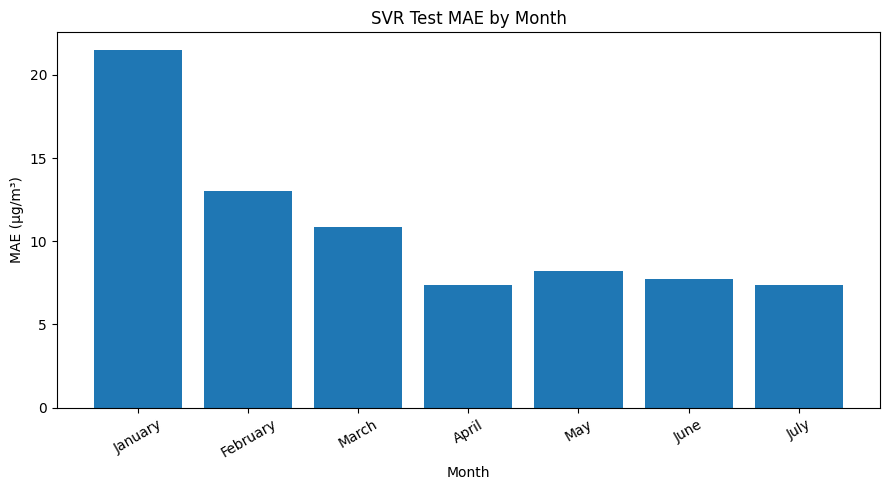

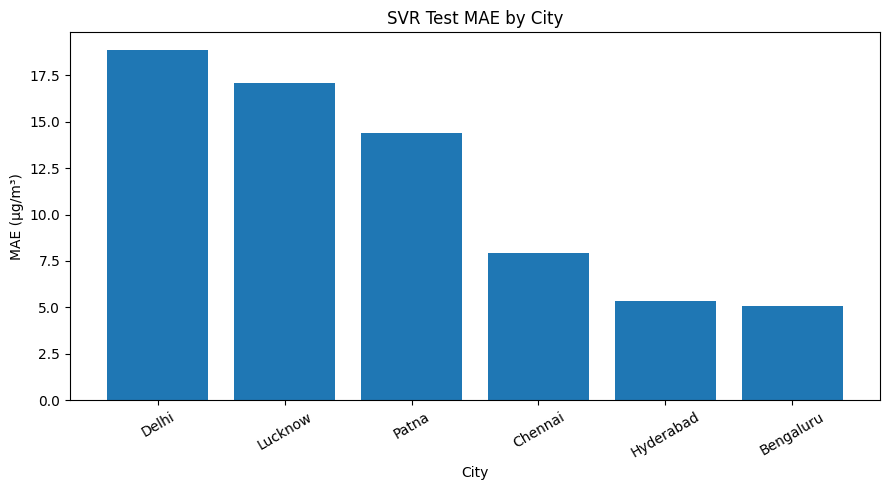

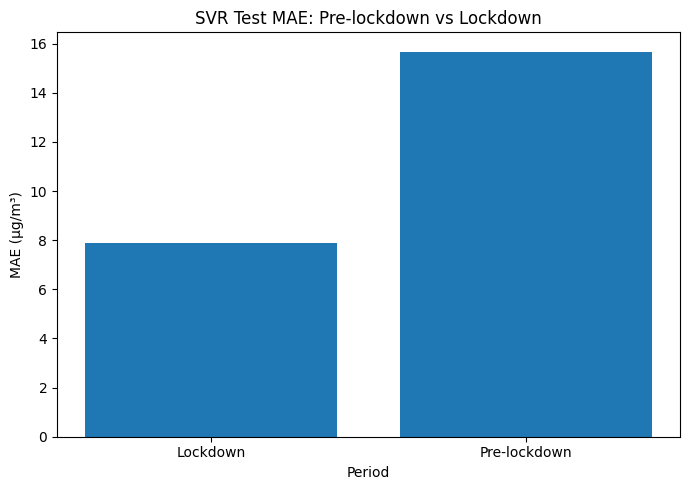

All three error-analysis charts saved.


In [59]:
import matplotlib.pyplot as plt

# 1. Monthly MAE
plt.figure(figsize=(9, 5))
plt.bar(
    monthly_errors["Month"].astype(str),
    monthly_errors["MAE"]
)
plt.title("SVR Test MAE by Month")
plt.xlabel("Month")
plt.ylabel("MAE (µg/m³)")
plt.xticks(rotation=30)
plt.tight_layout()

plt.savefig(
    os.path.join(figure_path, "test_mae_by_month.png"),
    dpi=300
)
plt.show()


# 2. City-wise MAE
plt.figure(figsize=(9, 5))
plt.bar(city_errors["City"], city_errors["MAE"])
plt.title("SVR Test MAE by City")
plt.xlabel("City")
plt.ylabel("MAE (µg/m³)")
plt.xticks(rotation=30)
plt.tight_layout()

plt.savefig(
    os.path.join(figure_path, "test_mae_by_city.png"),
    dpi=300
)
plt.show()


# 3. Period-wise MAE
plt.figure(figsize=(7, 5))
plt.bar(period_errors["Period"], period_errors["MAE"])
plt.title("SVR Test MAE: Pre-lockdown vs Lockdown")
plt.xlabel("Period")
plt.ylabel("MAE (µg/m³)")
plt.tight_layout()

plt.savefig(
    os.path.join(figure_path, "test_mae_by_period.png"),
    dpi=300
)
plt.show()


print("All three error-analysis charts saved.")

## Day 15 — Error Analysis Findings

### Finding 1: Model performance varied across months

The model recorded its highest monthly MAE in January 2020 (21.48 µg/m³), followed by February (13.02 µg/m³). The MAE decreased to 7.39 µg/m³ in April. This indicates that the model's prediction errors were substantially higher at the beginning of the test period. July had only six observations and was therefore excluded from meaningful monthly comparisons.

**Supporting evidence:** `test_mae_by_month.png` and `regression_test_errors_by_month.csv`.

### Finding 2: Model performance varied across cities

Delhi recorded the highest city-wise MAE (18.87 µg/m³), followed by Lucknow (17.09 µg/m³) and Patna (14.41 µg/m³). Bengaluru (5.08 µg/m³) and Hyderabad (5.35 µg/m³) had the lowest MAE values. This indicates that the model's prediction accuracy differed considerably across cities.

**Supporting evidence:** `test_mae_by_city.png` and `regression_test_errors_by_city.csv`.

### Finding 3: Lower prediction errors during the lockdown period

The lockdown period had an MAE of 7.87 µg/m³, compared with 15.68 µg/m³ during the pre-lockdown period. RMSE also decreased from 24.58 to 11.41 µg/m³. The model therefore performed better during the lockdown period in this test dataset. However, this difference does not establish that lockdown caused the improvement; seasonal patterns and changes in pollution conditions may also have contributed.

**Supporting evidence:** `test_mae_by_period.png` and `regression_test_errors_by_period.csv`.

### Additional observation: Largest individual prediction errors

All ten worst predictions occurred in January 2020. Delhi appeared five times, Lucknow three times and Patna twice. The largest error was 133.28 µg/m³ for Delhi on 1 January 2020, where the model substantially underpredicted the actual PM2.5 concentration.

Diwali and the usual late-year crop-burning period fall outside the test window (1 January–1 July 2020), so these events cannot explain the January errors based on the available test dates.

In [61]:
print("=== DAY 15 OUTPUT VERIFICATION ===")

required_files = [
    "worst_10_test_predictions.csv",
    "regression_test_errors_by_month.csv",
    "regression_test_errors_by_city.csv",
    "regression_test_errors_by_period.csv"
]

required_figures = [
    "test_mae_by_month.png",
    "test_mae_by_city.png",
    "test_mae_by_period.png"
]

for f in required_files:
    print(f, ":", os.path.exists(os.path.join(output_path, f)))

for f in required_figures:
    print(f, ":", os.path.exists(os.path.join(figure_path, f)))



=== DAY 15 OUTPUT VERIFICATION ===
worst_10_test_predictions.csv : True
regression_test_errors_by_month.csv : True
regression_test_errors_by_city.csv : True
regression_test_errors_by_period.csv : True
test_mae_by_month.png : True
test_mae_by_city.png : True
test_mae_by_period.png : True
